### Tetrode data

In [1]:
from pathlib import Path
import spikeinterface.full as si

%matplotlib widget

In [2]:
#base_data_folder = Path("/home/samuel/DataSpikeSorting/data_cns_lyon_2025/")
#working_folder = Path("/home/samuel/DataSpikeSorting/data_cns_lyon_2025/results")

# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "school_2026/data/")
results_folder = Path(home / "school_2026/results/")

recording_name = "1544_2023-04-21_09-55-34_of"

results_folder = results_folder / recording_name

In [10]:
recording = si.read_openephys(base_data_folder / recording_name, stream_name='Signals CH')

In [16]:
recording

OpenEphysLegacyRecordingExtractor: 16 channels - 30.0kHz - 1 segments - 66,593,792 samples 
                                   2,219.79s (37.00 minutes) - int16 dtype - 1.98 GiB

In [17]:
recording_processed = si.bandpass_filter(recording, freq_max=5000, dtype='float32')
#recording_processed = si.common_reference(recording_processed)

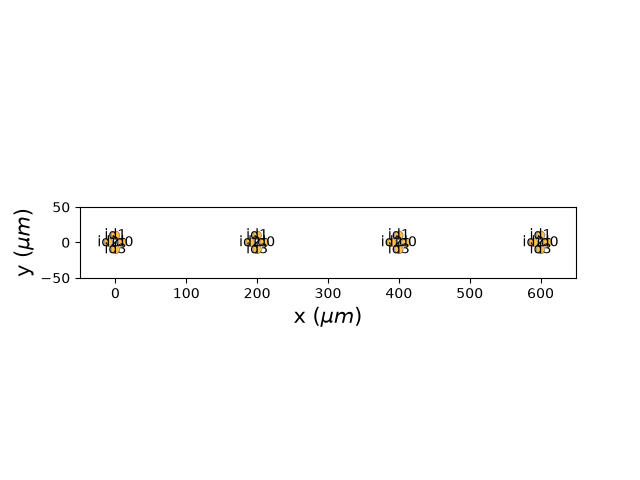

In [18]:
import probeinterface as pi
import probeinterface.plotting
import numpy as np
from probeinterface import generate_tetrode

probegroup = pi.ProbeGroup()
for i in range(4):
    tetrode = generate_tetrode()
    tetrode.move([i * 200, 0])
    probegroup.add_probe(tetrode)
probegroup.set_global_device_channel_indices(np.arange(16))
pi.plotting.plot_probegroup(probegroup, with_contact_id=True, same_axes=True)

In [21]:
recording_processed.set_probegroup(probegroup)
split_recordings = recording_processed.split_by("group")
# is a dict of recordings

In [22]:
si.set_global_job_kwargs(n_jobs=0.8)
sortings_lupin = si.run_sorter(sorter_name="lupin", recording=split_recordings, 
                           folder= results_folder / "sorter_lupin",
                           verbose=True, 
                           remove_existing_folder=True, 
                           apply_preprocessing=False, 
                           apply_motion_correction=False)


                            .::----::..
                 ..:-+#%*+#%@@@@@@@+..:+#+.
                .+@%%@@@@@@@@@@@@@@#:  .=@=
                -@@@@@@@@@@@@@@@@@@%-. .=@*
                .@@@@@@@@@@@@@@@@@@@*. .-%#
                 %@@@@@@@@@@@@@@@@@@*.  :#%
                 =%%@@@@@@@@@@@@@@%%+:  .+@.
                 -%#@@@@@@@@@@@@@@%*==  .-@.
                 :#%@@@@@@@@@@@@@@%#+#  .=@.
                 .+%@@@@@@@@@@@@@@@%#@. .+@.
                 .+*#@@@@@@@@@@@@@@@%@. .+@:
                 .=%+@@@@@@@@@@@@@@@@*.  =%-.
                  :#%##@@@@@@@@@@@@%%-.  :%+.
               ..:=**%@@@@@@@@@@@@@@@:.  .%%......
             .+#@%%%@**@%@@@@@@@@@@@*....=%@%@@@@@%=..
            .*@@@@@@@@@@@=#@@@@@@@@@@*=:.:.#@@@@@@%%-.
           .-%%@@@@@@@@@@@@@#+%@+-::-+=:=::+@@@@@@##-.
           .:%@@@@@@@@@@@@@@@@@%+%##*%%%**%@@@@@@##+.
            .+@@@@@@@@@@@@@@@@#***++***@@@@@@@@%%%=.
             .:*@@@@@@@@%=-.....   ....:-*%%%%%+-.
                 ..:-:..
                       

noise_level (workers: 20 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

get protoype waveforms (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

detect peaks (matched_filtering) (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

detect_peaks(): 60694 peaks found
select_peaks(): 20000 peaks kept for clustering


Fit peaks svd (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

... (44 outputs left out)

estimate_templates_with_accumulator (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

find spikes (wobble) (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


lupin run time 95.06s


In [23]:
sortings_lupin = sorting_lupin

In [27]:
analyzer = si.create_sorting_analyzer(sorting=sortings_lupin, recording=split_recordings)
analyzer.compute({
    "random_spikes" : {},
    "templates": {},
    "waveforms": {},
    "noise_levels": {},
    "correlograms": {},
    "noise_levels": {},
    "spike_amplitudes": {},
    "spike_locations": {},
    "template_metrics": {},
    "unit_locations": {},
    "template_similarity": {},
    "quality_metrics": {},
})

estimate_templates (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

estimate_templates (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

estimate_templates (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

estimate_templates (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/sortinganalyzer.py:259: FutureWarning: Passing sparsity and job arguments via keyword arguments will be deprecated in 0.106.0. Please pass them as a `sparsity_kwargs` or `job_kwargs` dictionary instead.
  return create_sorting_analyzer(


compute_waveforms (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?it/s]

noise_level (workers: 20 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Compute : spike_amplitudes + spike_locations (workers: 57 processes fork):   0%|          | 0/2220 [00:00<?, ?…

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/analyzer_extension_core.py:1207: UserWarning: The following metrics will not be computed due to missing dependencies: ['d_prime', 'nearest_neighbor', 'silhouette', 'mahalanobis']
  warnings.warn(
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divi

In [28]:
from spikeinterface_gui import run_mainwindow
run_mainwindow(
    analyzer,
    mode="desktop"
)

qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x4f118790 but 0x0 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x4f118790 but 0x0 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x4f118790 but 0x0 is focused


<spikeinterface_gui.backend_qt.QtMainWindow(0x4cfce8d0) at 0x77572a367c00>